# Módulo 15 · Semana 15, Reducción de dimensionalidad y muestreo
Juan Esteban Camacho Castro, Juan Diego Serpa Ruiz

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE
from sklearn.impute import SimpleImputer


## Abrir el notebook y cargar el dataset de features seleccionadas

In [2]:
df = pd.read_csv("novamarket_features_seleccionadas.csv")

In [3]:
df.columns

Index(['nivel_lealtad_cod', 'canal_App', 'es_venta_corporativa',
       'edad_cliente', 'gasto_promedio', 'precio_unitario', 'monto_compra',
       'dias_desde_ultima_compra', 'fuga_cliente', 'id_cliente'],
      dtype='object')

## Dividir en entrenamiento y prueba antes de cualquier otra cosa

In [4]:
X = df.drop(columns=["fuga_cliente", "id_cliente"])
y = df["fuga_cliente"]

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=df["fuga_cliente"]
)

In [6]:
imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

In [7]:
print("Valores faltantes en X_train:")
print(X_train.isnull().sum())

print("\nTotal de valores faltantes:")
print(X_train.isnull().sum().sum())

Valores faltantes en X_train:
nivel_lealtad_cod           0
canal_App                   0
es_venta_corporativa        0
edad_cliente                0
gasto_promedio              0
precio_unitario             0
monto_compra                0
dias_desde_ultima_compra    0
dtype: int64

Total de valores faltantes:
0


In [8]:
print("Proporción en entrenamiento:")
print(y_train.value_counts(normalize=True))

print("\nProporción en prueba:")
print(y_test.value_counts(normalize=True))

Proporción en entrenamiento:
fuga_cliente
0    0.790889
1    0.209111
Name: proportion, dtype: float64

Proporción en prueba:
fuga_cliente
0    0.790885
1    0.209115
Name: proportion, dtype: float64


In [9]:
print("Dimensiones de entrenamiento:", X_train.shape)
print("Dimensiones de prueba:", X_test.shape)

Dimensiones de entrenamiento: (479200, 8)
Dimensiones de prueba: (119800, 8)


## Escalar las features numéricas del conjunto de entrenamiento

In [10]:
columnas_numericas = X_train.select_dtypes(include=["int64", "float64"]).columns

In [11]:
scaler = StandardScaler()

X_train[columnas_numericas] = scaler.fit_transform(X_train[columnas_numericas])

X_test[columnas_numericas] = scaler.transform(X_test[columnas_numericas])

In [12]:
print("Medias de X_train:")
print(X_train[columnas_numericas].mean().round(4))

Medias de X_train:
nivel_lealtad_cod           0.0
canal_App                   0.0
es_venta_corporativa        0.0
edad_cliente               -0.0
gasto_promedio             -0.0
precio_unitario             0.0
monto_compra               -0.0
dias_desde_ultima_compra    0.0
dtype: float64


In [13]:
print("\nDesviaciones estándar de X_train:")
print(X_train[columnas_numericas].std().round(4))


Desviaciones estándar de X_train:
nivel_lealtad_cod           1.0
canal_App                   1.0
es_venta_corporativa        1.0
edad_cliente                1.0
gasto_promedio              1.0
precio_unitario             1.0
monto_compra                1.0
dias_desde_ultima_compra    1.0
dtype: float64


## Revisar la matriz de correlación para decidir si PCA hace falta

In [14]:
correlacion = X_train.corr()

correlacion

,nivel_lealtad_cod,canal_App,es_venta_corporativa,edad_cliente,gasto_promedio,precio_unitario,monto_compra,dias_desde_ultima_compra
nivel_lealtad_cod,1.000000,-0.001737,-0.000130,0.001645,0.001634,-0.001135,0.000624,0.000916
canal_App,-0.001737,1.000000,0.000302,-0.001213,0.000103,-0.000522,-0.000607,0.000301
es_venta_corporativa,-0.000130,0.000302,1.000000,0.000812,0.345624,0.329915,0.685914,0.001046
edad_cliente,0.001645,-0.001213,0.000812,1.000000,0.001187,0.000524,0.001260,-0.001681
gasto_promedio,0.001634,0.000103,0.345624,0.001187,1.000000,0.308130,0.503498,0.002986
precio_unitario,-0.001135,-0.000522,0.329915,0.000524,0.308130,1.000000,0.611210,0.001218
monto_compra,0.000624,-0.000607,0.685914,0.001260,0.503498,0.611210,1.000000,0.001975
dias_desde_ultima_compra,0.000916,0.000301,0.001046,-0.001681,0.002986,0.001218,0.001975,1.000000


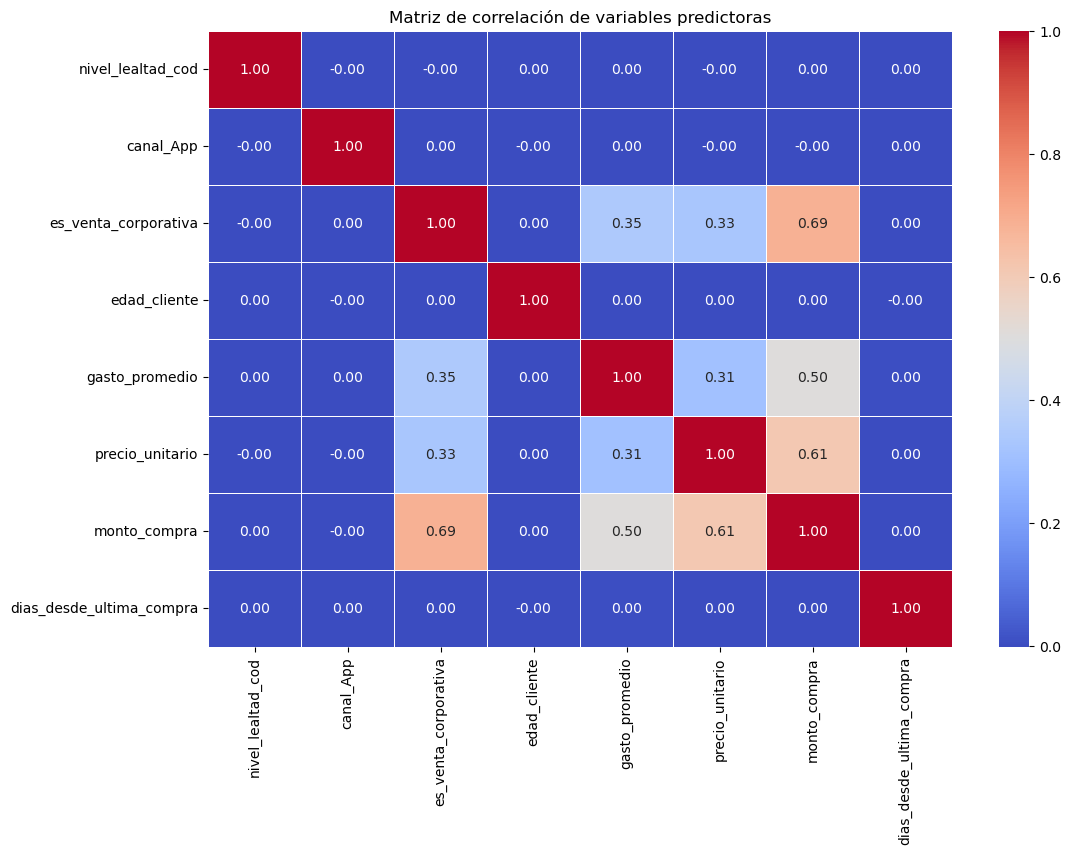

In [15]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlacion,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Matriz de correlación de variables predictoras")
plt.show()

In [16]:
correlaciones_altas = correlacion.where(
    np.triu(np.ones(correlacion.shape), k=1).astype(bool)
).stack()

correlaciones_altas = correlaciones_altas[
    correlaciones_altas.abs() > 0.6
].sort_values(key=abs, ascending=False)

print("Pares de variables con correlación superior a 0.6:")
print(correlaciones_altas)

Pares de variables con correlación superior a 0.6:
es_venta_corporativa  monto_compra    0.685914
precio_unitario       monto_compra    0.611210
dtype: float64


**Conclusión:**

La matriz de correlación muestra muy poca redundancia entre las variables predictoras. Casi todos los pares tienen correlaciones cercanas a 0 (del orden de 0.001 a 0.003), y solo dos pares superan el umbral de 0.6: `es_venta_corporativa` con `monto_compra` (0.69) y `precio_unitario` con `monto_compra` (0.61). Ambas relaciones tienen sentido de negocio: las ventas corporativas y los precios altos elevan el monto de la compra. Fuera de ese pequeño grupo, las variables aportan información en gran parte independiente, así que no hay un problema fuerte de multicolinealidad que justifique por sí solo comprimir las features.

## Ajustar PCA sobre el entrenamiento y transformar ambos conjuntos

In [17]:
pca = PCA(n_components=0.90)

In [18]:
pca.fit(X_train)

PCA(n_components=0.9)

In [19]:
X_train_pca = pca.transform(X_train)
X_test_pca = pca.transform(X_test)

In [20]:
pca.explained_variance_ratio_.cumsum()

array([0.30274049, 0.42813947, 0.5532814 , 0.67810669, 0.80274205,
       0.89025759, 0.97313053])

## Documentar la decisión, la usaste o no

Decisión: no usar PCA en este caso.

Con n_components=0.90, PCA conservó 7 componentes de las 8 variables originales (la varianza acumulada con 6 componentes es 0.89, apenas por debajo del 90%, y con 7 llega a 0.97). Solo se elimina una dimensión, así que la reducción es mínima.

Con apenas 8 features no hay un problema de dimensionalidad que resolver, y la cuestión es perder interpretabilidad: los componentes son combinaciones lineales de todas las variables y ya no se pueden explicar en términos de negocio (edad, monto, canal, etc.).

Por eso se conservan las 8 features originales (escaladas) para el modelado. PCA solo valdría la pena con muchas más variables o con una multicolinealidad severa.

## Verificar el desbalance real de fuga_cliente

In [21]:
y_train.value_counts()

fuga_cliente
0    378994
1    100206
Name: count, dtype: int64

In [22]:
y_train.value_counts(normalize=True)

fuga_cliente
0    0.790889
1    0.209111
Name: proportion, dtype: float64

Hay 378994 clientes sin fuga (0.79) frente a 100206 clientes con fuga (0.21). El desbalance es moderado (aprox. 3.8 a 1), pero suficiente para que un modelo entrenado sin corregirlo tienda a favorecer la clase mayoritaria (no fuga) y detecte peor a los clientes que sí se van, que son justamente los de interés para el negocio.

## Aplicar undersampling sobre el conjunto de entrenamiento

In [23]:
rus = RandomUnderSampler(random_state=42)
X_train_under, y_train_under = rus.fit_resample(X_train, y_train)

In [24]:
y_train_under.value_counts()

fuga_cliente
0    100206
1    100206
Name: count, dtype: int64

## Aplicar oversampling sobre el conjunto de entrenamiento

In [25]:
ros = RandomOverSampler(random_state=42)
X_train_over, y_train_over = ros.fit_resample(X_train, y_train)

In [26]:
y_train_over.value_counts()

fuga_cliente
0    378994
1    378994
Name: count, dtype: int64

## Aplicar SMOTE sobre el conjunto de entrenamiento

In [27]:
X_train.dtypes

nivel_lealtad_cod           float64
canal_App                   float64
es_venta_corporativa        float64
edad_cliente                float64
gasto_promedio              float64
precio_unitario             float64
monto_compra                float64
dias_desde_ultima_compra    float64
dtype: object

In [28]:
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

In [29]:
y_train_smote.value_counts()

fuga_cliente
0    378994
1    378994
Name: count, dtype: int64

## Comparar las tres versiones y elegir la que usarás

In [30]:
def resumen_version(nombre, X_v, y_v):
    conteo = y_v.value_counts().sort_index()
    # Duplicadas = filas idénticas (features + clase) que ya aparecieron antes
    n_dup = pd.concat(
        [X_v.reset_index(drop=True), y_v.reset_index(drop=True)], axis=1
    ).duplicated().sum()
    return {
        "Versión": nombre,
        "Total de filas": len(X_v),
        "Filas clase 0 (sin fuga)": conteo.get(0, 0),
        "Filas clase 1 (fuga)": conteo.get(1, 0),
        "Filas duplicadas": n_dup,
        "¿Hay duplicados?": "Sí" if n_dup > 0 else "No",
    }

tabla_comparativa = pd.DataFrame([
    resumen_version("Undersampling", X_train_under, y_train_under),
    resumen_version("Oversampling", X_train_over, y_train_over),
    resumen_version("SMOTE", X_train_smote, y_train_smote),
]).set_index("Versión")

tabla_comparativa

,Total de filas,Filas clase 0 (sin fuga),Filas clase 1 (fuga),Filas duplicadas,¿Hay duplicados?
Versión,,,,,
Undersampling,200412,100206,100206,0,No
Oversampling,757988,378994,378994,278788,Sí
SMOTE,757988,378994,378994,0,No


## Decisión final: ¿qué versión uso?

Versión elegida: SMOTE.

**Lectura de la tabla comparativa:**

| Versión | Total de filas | Clase 0 | Clase 1 | Filas duplicadas |
|---|---|---|---|---|
| Undersampling | 200,412 | 100,206 | 100,206 | 0 |
| Oversampling | 757,988 | 378,994 | 378,994 | 278,788 |
| SMOTE | 757,988 | 378,994 | 378,994 | 0 |

Las tres versiones quedan perfectamente balanceadas (50% / 50%), pero difieren en cuántos datos conservan y en cuántas filas repiten. El conjunto original de entrenamiento no tiene filas duplicadas, así que todos los duplicados de oversampling (278,788, exactamente la diferencia entre las dos clases) son copias creadas artificialmente.

Por qué se elegió:

El Smote equilibra las clases conservando las 378,994 filas de la clase mayoritaria y sin repetir ninguna fila (0 duplicados). En lugar de copiar clientes en fuga, genera ejemplos sintéticos interpolando entre vecinos de la clase minoritaria, lo que reduce el riesgo de que el modelo memorice casos puntuales. Es el mejor equilibrio entre balance y riesgo de sobreajuste.
Mientras que el undersampling, para igualar las clases elimina 278,788 filas de clientes sin fuga (cerca del 74% de esa clase) y deja solo 200,412 filas en total, con lo que se pierde información sobre el comportamiento de los clientes que sí se quedan. Su ventaja es que es la opción más rápida de entrenar.
En cuanto al oversampling repite exactamente los mismos 100,206 clientes en fuga hasta completar 378,994, lo que genera 278,788 filas duplicadas. El modelo ve muchas veces los mismos casos, lo que favorece el sobreajuste y hace que las métricas de validación se vean mejores de lo que serán con datos nuevos.

## Guardar el dataset de entrenamiento balanceado y la prueba intacta

In [31]:
train_balanceado = pd.concat([X_train_smote.reset_index(drop=True), y_train_smote.reset_index(drop=True)],axis=1)

test = pd.concat([X_test, y_test], axis=1)

train_balanceado.to_csv("novamarket_train_balanceado.csv", index=False)
test.to_csv("novamarket_test.csv", index=False)

train_leido = pd.read_csv("novamarket_train_balanceado.csv")
test_leido = pd.read_csv("novamarket_test.csv")

print("Train balanceado:", train_leido.shape)
print(train_leido["fuga_cliente"].value_counts(normalize=True))

print("\nTest:", test_leido.shape)
print(test_leido["fuga_cliente"].value_counts(normalize=True))

Train balanceado: (757988, 9)
fuga_cliente
0    0.5
1    0.5
Name: proportion, dtype: float64

Test: (119800, 9)
fuga_cliente
0    0.790885
1    0.209115
Name: proportion, dtype: float64
